# Chapitre 5 - Cours 7 : workflows et exécution durable

Un mode de flux de données apparu dans la 2e édition du livre : les **moteurs de
workflows**. Dans une architecture de services, un traitement métier (un paiement)
enchaîne plusieurs appels à des services différents. Que se passe-t-il si le processus
qui orchestre ces appels tombe au milieu ? L'**exécution durable** répond en journalisant
chaque appel pour pouvoir **rejouer** le traitement sans refaire ce qui a déjà réussi. Ce
cours construit un mini-moteur d'exécution durable (`ddia/durable.py`, une centaine de
lignes) pour en voir le principe, la fenêtre dangereuse et les contraintes. Il couvre la
section *Durable Execution and Workflows*.

**Plan.**

1. Workflows, tâches et moteurs.
2. Le problème : une panne au milieu d'un paiement.
3. Journaliser et rejouer.
4. La fenêtre dangereuse et les clés d'idempotence.
5. Le prix du rejeu : déterminisme et code qui change.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia.durable import (Crash, Engine, ExternalService, NonDeterminismError, crash_once, crash_randomly)
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 70)

## 1. Workflows, tâches et moteurs (section *Durable Execution and Workflows*)

Prenons l'exemple du livre : une application de paiement débite une carte bancaire et
dépose les fonds sur un compte. Plusieurs services s'en partagent les étapes : détection
de fraude, intégration avec les cartes, intégration bancaire. Traiter **un** paiement
demande donc plusieurs appels : vérifier la fraude, débiter la carte, déposer à la
banque. Cette suite d'étapes s'appelle un **workflow**, et chaque étape une **tâche**
(Temporal parle d'« activité », d'autres de « fonction durable »). On décrit un workflow
comme un graphe de tâches, dans un langage de programmation, un langage dédié ou une
notation comme BPMN.

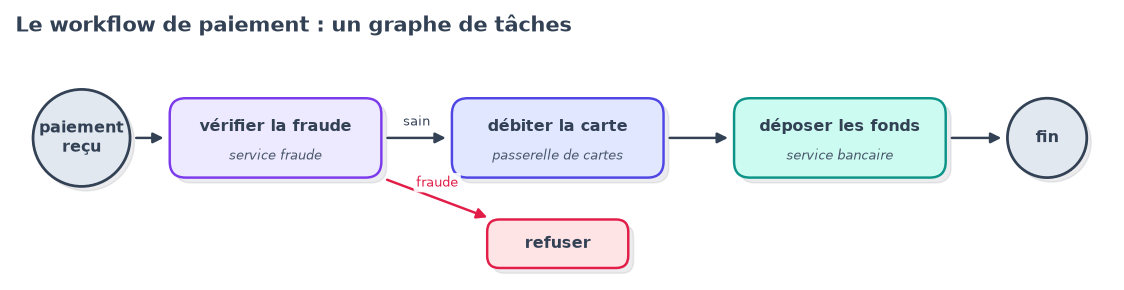

In [2]:
d = Diagram(12.5, 2.5, title="Le workflow de paiement : un graphe de tâches")
d.box("debut", 0.8, 1.6, "paiement\nreçu", color=SLATE, kind="circle", w=1.1)
d.box("fraude", 3.0, 1.6, "vérifier la fraude", sub="service fraude", color=VIOLET, w=2.4)
d.box("carte", 6.2, 1.6, "débiter la carte", sub="passerelle de cartes", color=INDIGO, w=2.4)
d.box("banque", 9.4, 1.6, "déposer les fonds", sub="service bancaire", color=TEAL, w=2.4)
d.box("fin", 11.75, 1.6, "fin", color=SLATE, kind="circle", w=0.9)
d.box("refus", 6.2, 0.4, "refuser", color=ROSE, w=1.6, h=0.55)
d.arrow("debut", "fraude"); d.arrow("fraude", "carte", "sain"); d.arrow("carte", "banque"); d.arrow("banque", "fin")
d.arrow("fraude", "refus", "fraude", color=ROSE)
d.show()

Un **moteur de workflows** exécute ces graphes : il décide quand et sur quelle machine
lancer chaque tâche, quoi faire si elle échoue (la machine plante), combien de tâches
peuvent tourner en parallèle. Il se compose en général d'un **orchestrateur**, qui
planifie les tâches, et d'**exécuteurs**, qui les exécutent. Un workflow est déclenché
par un calendrier (toutes les heures), par un service web, voire par un humain. Il en
existe pour bien des usages : orchestrer des traitements ETL (Airflow, Dagster, Prefect),
faire décrire les processus par des non-informaticiens en notation graphique (Camunda,
Orkes), ou offrir l'**exécution durable** (Temporal, Restate).

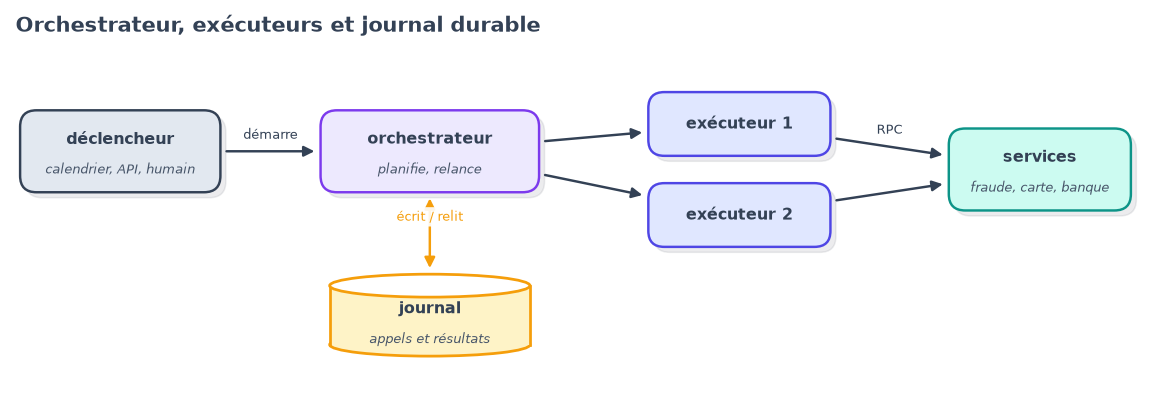

In [3]:
d = Diagram(12.5, 3.6, title="Orchestrateur, exécuteurs et journal durable")
d.box("trig", 1.2, 2.6, "déclencheur", sub="calendrier, API, humain", color=SLATE, w=2.2)
d.box("orch", 4.6, 2.6, "orchestrateur", sub="planifie, relance", color=VIOLET, w=2.4)
d.box("log", 4.6, 0.8, "journal", sub="appels et résultats", color=AMBER, kind="db", w=2.2, h=0.9)
d.box("ex1", 8.0, 2.9, "exécuteur 1", color=INDIGO, w=2.0, h=0.7)
d.box("ex2", 8.0, 1.9, "exécuteur 2", color=INDIGO, w=2.0, h=0.7)
d.box("svc", 11.3, 2.4, "services", sub="fraude, carte, banque", color=TEAL, w=2.0)
d.arrow("trig", "orch", "démarre")
d.arrow("orch", "log", "écrit / relit", both=True, color=AMBER)
d.arrow("orch", "ex1"); d.arrow("orch", "ex2")
d.arrow("ex1", "svc", "RPC"); d.arrow("ex2", "svc")
d.show()

> **À retenir.** Un workflow est un graphe de tâches (souvent des appels de services) ; un
> moteur de workflows (orchestrateur et exécuteurs) les planifie, les exécute et gère les
> pannes.